# Unidad 38 — Datos de series temporales

Semana 6 · Clase 1 · Fuente: PDF parte 1, págs. 74–162

[Índice de la semana](../semana-06.ipynb) | [Anterior](u37-ordenacion-de-datos.ipynb) | [Siguiente](../clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Objetivos de la unidad

Según el PDF (pág. 74):

- Determinar si un marco de datos presenta un objetivo de análisis que utiliza datos de series temporales.
- Explicar los dos tipos de datos de series temporales.
- Crear datos de fecha, hora, intervalo y matriz como tipo de datos de series temporales.
- Indexar y trocear un marco de datos utilizando `DatetimeIndex`.
- Obtener una media móvil, estadística descriptiva representativa de los datos de series temporales.
- Visualizar datos en forma de gráfico de área para comparar dos o más series de datos.

Conceptos previos que el PDF da por sabidos (pág. 75): indexar y trocear marcos de datos y series, crear un marco de datos a partir de un archivo externo, dibujar gráficos con Matplotlib, ver el resumen con `DataFrame.info()` y recuperar o sustituir datos faltantes.

Palabras clave (pág. 76): datos de series temporales, marca de tiempo (`Timestamp`), periodo (`Period`), media móvil, gráfico de áreas y datos categóricos.

**Referencia:** PDF parte 1, págs. 74–76

## Contexto

La misión de la unidad (págs. 78–80) pregunta algo sobre el negocio mundial del marisco: ¿la mayor parte del pescado se captura directamente en el mar o se produce mediante acuicultura? La organización Our World in Data publica cifras anuales por país de ambas fuentes. El trabajo consiste en convertir ese archivo CSV en una serie temporal indexada por año, limpiarlo, sumar la producción mundial, graficar la tendencia desde la década de 1960 y comparar al menos tres países.

Antes de llegar ahí, la unidad recorre las herramientas de pandas para fechas y horas: `Timestamp`, `Timedelta`, `Period`, `to_datetime`, `DatetimeIndex`, `date_range`, `period_range` y las ventanas móviles con `rolling()`.

El PDF fija la fecha de descarga de los datos (6 de noviembre de 2021) y los entrega como archivo local. En este cuaderno los datos están en `../datos/` con el prefijo `u38-`. Los detalles de cada archivo se explican donde se usan.

**Referencia:** PDF parte 1, págs. 78–80

In [2]:
import warnings
import datetime
from datetime import date, datetime, time, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("pandas", pd.__version__)

pandas 3.1.0


## 1. ¿Qué son los datos de series temporales?

Una **serie temporal** es un conjunto de valores organizados en el tiempo, recogidos a lo largo de un periodo determinado. El PDF la define de forma más técnica: datos sobre una o más variables medidos durante un periodo de tiempo a intervalos específicos.

Se usan para el análisis predictivo empresarial: precio de las acciones, presupuesto, ventas, flujo de activos, mantenimiento y previsión de ventas. Allí se combinan la tendencia, la periodicidad y la estacionalidad para predecir indicadores futuros. Pandas fue creado para manejar datos financieros, por lo que este análisis es uno de sus núcleos. Fuera de las finanzas se aplica en medicina, meteorología, astronomía, economía e IoT.

El PDF (pág. 83) muestra como ejemplo real el Índice de Gestión de Compras (PMI) del sector manufacturero de Estados Unidos: un valor superior a 50 indica expansión económica y uno inferior, contracción. Es un indicador adelantado de los resultados económicos generales, y se compara la cifra prevista con la real.

Dos observaciones del PDF (pág. 84):

- Los datos están ordenados por tiempo, así que hay valores de observación continuos y es muy probable que cada valor esté correlacionado con los vecinos.
- Al cargar datos externos, la columna de fechas casi siempre llega como cadena u objeto. El primer paso de un análisis efectivo es convertirla al tipo de series temporales de pandas.

**Clave:** si el orden en el tiempo importa y hay una fecha asociada a cada observación, es un problema de series temporales.

**Referencia:** PDF parte 1, págs. 82–84

## 2. Los dos tipos de datos y los cuatro elementos

### Dos tipos en pandas (pág. 85)

| Tipo | Qué representa | Clase de pandas |
|---|---|---|
| `Timestamp` (marca de tiempo) | un punto específico en el tiempo, representado con el tipo `datetime64` | `pd.Timestamp` |
| Periodo | un intervalo constante entre dos marcas de tiempo | `pd.Period` |

Varias marcas de tiempo reunidas en una matriz forman un `DatetimeIndex`. El esquema del PDF muestra cuatro marcas (`2021-01-01`, `2021-04-02`, `2021-07-02`, `2021-10-01`) y tres periodos que las separan.

### Cuatro elementos (págs. 86–87)

| Elemento | Descripción |
|---|---|
| Tendencia | patrón fluctuante a largo plazo; los valores aumentan o disminuyen de forma razonablemente predecible |
| Estacional | patrón que se repite en una unidad de tiempo fija: semana, mes, trimestre, semestre |
| Ciclo | fluctuación a largo plazo sin frecuencia fija, de al menos dos años, a menudo por condiciones económicas |
| Al azar | patrón totalmente irregular que no pertenece a las tres categorías anteriores |

Para descubrir ideas hay que descomponer una serie en estos componentes. Ese análisis se llama **modelo aditivo de series temporales**:

> Factor de tendencia + Factor de ciclo + Factor estacional + Factor irregular/aleatorio

**Ampliación (no está en el PDF):** el siguiente ejemplo construye una serie sintética sumando una tendencia, un componente estacional anual y ruido aleatorio. Así se ve que la serie observada es la suma de sus componentes.

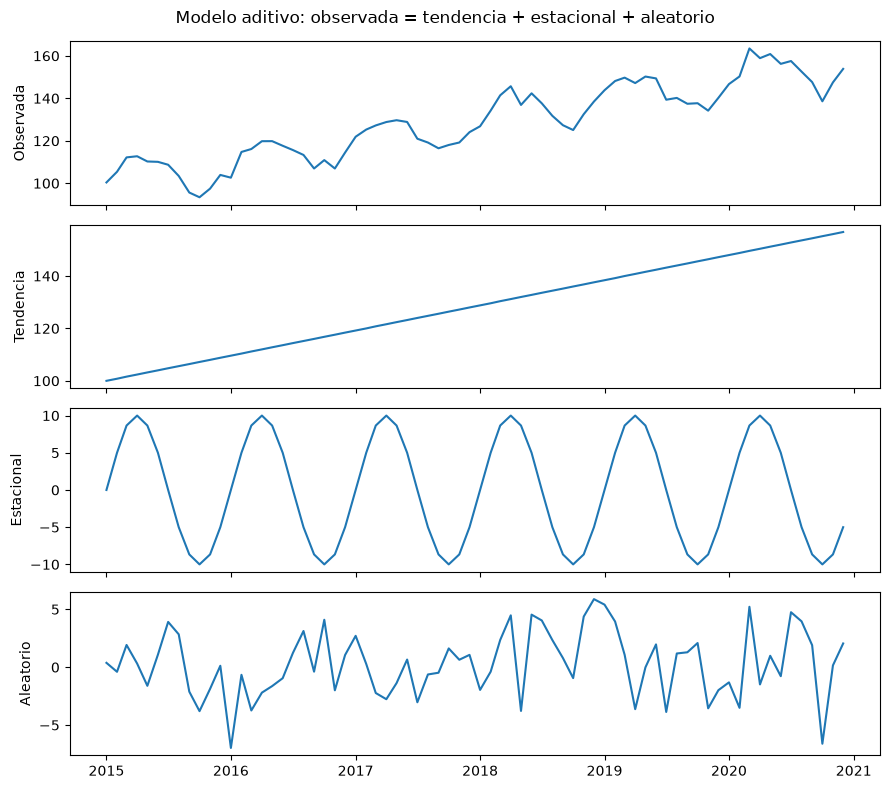

In [3]:
# Serie mensual sintética: observada = tendencia + estacional + aleatorio
meses = pd.period_range("2015-01", periods=72, freq="M")
t = np.arange(72)
tendencia = 100 + 0.8 * t
estacional = 10 * np.sin(2 * np.pi * t / 12)
azar = np.random.default_rng(0).normal(0, 3, 72)
observada = tendencia + estacional + azar

fig, ejes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
x = meses.to_timestamp()
for eje, (nombre, valores) in zip(ejes, [("Observada", observada), ("Tendencia", tendencia),
                                          ("Estacional", estacional), ("Aleatorio", azar)]):
    eje.plot(x, valores)
    eje.set_ylabel(nombre)
fig.suptitle("Modelo aditivo: observada = tendencia + estacional + aleatorio")
plt.tight_layout()
plt.show()

**Clave:** `Timestamp` es un punto; `Period` es un tramo con inicio y fin. El modelo aditivo suma tendencia, ciclo, estacionalidad y azar.

**Para el quiz:** la tendencia es a largo plazo; lo estacional se repite en periodos fijos; el ciclo no tiene frecuencia fija y dura al menos dos años.

**Referencia:** PDF parte 1, págs. 85–87

## 3. Fechas y horas con la clase `datetime` de Python

El objeto `datetime` forma parte de la librería estándar `datetime` de Python. Sirve para expresar un punto específico en el tiempo con fecha y hora, solo la fecha o solo la hora. Recibe año, mes, día, hora, minuto, segundo, microsegundo y zona horaria. Solo los tres primeros son obligatorios; si se omiten los demás, valen 0. El PDF advierte una desventaja: reduce la precisión necesaria para cálculos masivos sobre series temporales. Por eso se convierte a `Timestamp` de pandas.

Ejemplos del PDF (págs. 89–92):

In [4]:
print(datetime(2021, 7, 7))             # año, mes y día; hora y minutos valen 0 por defecto
print(repr(datetime(2021, 7, 7)))
print(repr(datetime(2021, 7, 7, 15, 50)))   # con hora y minutos

2021-07-07 00:00:00
datetime.datetime(2021, 7, 7, 0, 0)
datetime.datetime(2021, 7, 7, 15, 50)


In [5]:
# combine() crea un datetime a partir de un objeto date y un objeto time existentes
d = date(2021, 7, 7)
t = time(13, 26, 10)
print(repr(datetime.combine(d, t)))

datetime.datetime(2021, 7, 7, 13, 26, 10)


In [6]:
# Los valores de "ahora" cambian en cada ejecución (en el PDF: 2021-11-07)
print(repr(datetime.now()))                    # fecha y hora actuales, hora local
print(repr(datetime.now(timezone.utc)))        # con zona horaria: se crea un datetime con tzinfo
print(repr(datetime.now().date()))             # solo la fecha
print(repr(datetime.now().time()))             # solo la hora

datetime.datetime(2026, 10, 22, 9, 35, 22, 719028)
datetime.datetime(2026, 10, 22, 14, 35, 22, 719065, tzinfo=datetime.timezone.utc)
datetime.date(2026, 10, 22)
datetime.time(9, 35, 22, 719102)


**Nota sobre el PDF:** en las diapositivas la importación `import datetime` y luego `from datetime import date, datetime, time, timezone` deja el nombre `datetime` apuntando a la clase, no al módulo. Es el comportamiento que usan los ejemplos y el que se mantiene aquí. La salida depende del momento de ejecución, por eso no coincide con la del PDF.

**Error común:** llamar `datetime(2021, 7)` sin el día lanza `TypeError`; se necesitan al menos año, mes y día.

**Referencia:** PDF parte 1, págs. 88–92

## 4. Un punto en el tiempo con `pd.Timestamp`

La fecha y la hora creadas con `datetime` también se crean con `pandas.Timestamp()`. La diferencia que señala el PDF es que su tipo es `datetime64`, con mayor precisión que el `datetime` de Python. Admite cadenas en varios formatos.

Ejemplos del PDF (págs. 94–95):

In [7]:
print(repr(pd.Timestamp('2017, 1, 15')))        # fecha: la hora queda en 00:00:00
print(repr(pd.Timestamp('2017, 5, 3, 12:00')))  # fecha y hora
print(repr(pd.Timestamp('12:00')))              # solo hora: se aplica la fecha de hoy

Timestamp('2017-01-15 00:00:00')
Timestamp('2017-05-03 12:00:00')
Timestamp('2026-10-22 12:00:00')


**Nota sobre el PDF:** en pandas 3 la unidad de tiempo por defecto de un `Timestamp` o `datetime64` creado desde texto es microsegundos (`datetime64[us]`), no nanosegundos (`datetime64[ns]`) como mostraba pandas 1.x. Se puede forzar la resolución con `.as_unit("ns")`. Para este curso la diferencia no cambia ningún resultado.

In [8]:
ts = pd.Timestamp('2017-05-03 12:00')
print(ts.year, ts.month, ts.day, ts.hour, ts.day_name())   # atributos (ampliación)
print(ts.unit, ts.as_unit("ns").unit)

2017 5 3 12 Wednesday
us ns


**Ampliación (no está en el PDF):** un `Timestamp` expone atributos como `year`, `month`, `day`, `hour` y el método `day_name()`.

**Referencia:** PDF parte 1, págs. 93–95

## 5. Intervalos de tiempo con `pd.Timedelta`

Hasta aquí se crearon momentos. Para expresar **intervalos** se usa `pandas.Timedelta(valor, unidad=None, **kwargs)`, subclase de `datetime.timedelta`. Es importante porque se necesita para determinar el número de días entre fechas o para analizar por un intervalo específico.

Ejemplo del PDF (págs. 97–99): ¿cuánto falta, o cuánto pasó, desde una fecha de cumpleaños?

In [9]:
my_birth = datetime(1973, 7, 7)
today = datetime.today()
tommorow = today + pd.Timedelta(days=1)      # se suma un día con Timedelta

print(tommorow - my_birth)                   # la resta de dos fechas devuelve un timedelta
print(my_birth - today)                      # resultado negativo: my_birth es anterior a today

19466 days, 9:35:22.727323
-19466 days, 14:24:37.272677


In [10]:
# Aritmética con horas
today = datetime.today()
data = today + pd.Timedelta(hours=10)

print(today)
print(data)                                  # se añadieron 10 horas

2026-10-22 09:35:22.729654
2026-10-22 19:35:22.729654


**Nota sobre el PDF:** el PDF usa la variable `tommorow` (con la errata) y fechas "de hoy" de 2021; los resultados (`17656 days`) dependen del día de ejecución. Para obtener un resultado reproducible se fija la fecha en lugar de `today()`:

In [11]:
referencia = datetime(2021, 11, 7)
dif = referencia - my_birth
print(dif, "->", dif.days, "días")
print(pd.Timedelta(days=1, hours=10), pd.Timedelta("90min"), pd.Timedelta(hours=10).total_seconds())

17655 days, 0:00:00 -> 17655 días
1 days 10:00:00 0 days 01:30:00 36000.0


**Clave:** restar dos fechas devuelve un `timedelta`; sumar un `Timedelta` a una fecha devuelve otra fecha.

**Referencia:** PDF parte 1, págs. 96–99

## 6. Un periodo con `pd.Period`

Muchos análisis de series temporales examinan eventos de un intervalo específico, como las ventas de una empresa durante un mes. Con marcas de tiempo es difícil agrupar y operar con intervalos; por eso pandas ofrece `Period`, un intervalo estandarizado basado en una **frecuencia** (diaria, semanal, mensual, anual, trimestral...). Un `Period` conoce su hora de inicio y de fin.

Ejemplo del PDF (pág. 100): un periodo de un mes basado en julio de 1973.

In [12]:
special_day = pd.Period('1973-7', freq='M')
special_day

Period('1973-07', 'M')

In [13]:
# Atributos start_time y end_time
print(repr(special_day.start_time))
print(repr(special_day.end_time))

Timestamp('1973-07-01 00:00:00')
Timestamp('1973-07-31 23:59:59.999999')


**Nota sobre el PDF:** el PDF muestra `end_time` como `1973-07-31 23:59:59.999999999` (nanosegundos). En pandas 3, con resolución de microsegundos, se obtiene `1973-07-31 23:59:59.999999`. El significado es el mismo: el último instante del mes.

El periodo se desplaza con aritmética simple. La suma de un entero mueve el periodo en **su propia unidad**; como `special_day` es mensual, `+ 2` desplaza dos meses (pág. 102).

In [14]:
n = special_day + 2

print(special_day)
print(n)

1973-07
1973-09


In [15]:
# pandas sabe cuántos días tiene cada mes (septiembre de 1973 tiene 30)
print(repr(n))
print(n.start_time, n.end_time)

Period('1973-09', 'M')
1973-09-01 00:00:00 1973-09-30 23:59:59.999999


**Error común:** pensar que `+ 2` siempre suma "dos meses". Suma dos **unidades de la frecuencia** del periodo: con `freq='D'` serían dos días y con `freq='Y'` (anual), dos años.

**Referencia:** PDF parte 1, págs. 100–103

## 7. De otros tipos a `datetime64`: `pd.to_datetime` e indexación con `DatetimeIndex`

`pandas.to_datetime(arg, errors=..., dayfirst=False, yearfirst=False, utc=None, format=None, exact=True, unit=None, origin='unix', cache=True)` convierte cadenas y otros tipos a `datetime64`. La clave del trabajo con series temporales es **indexar con un objeto `DatetimeIndex`**: el marco de datos queda ordenado por fecha y hora y se puede trocear con fechas.

El PDF usa como ejemplo el precio internacional del petróleo crudo WTI de la Reserva Federal (FRED), serie `DCOILWTICO`.

**Nota sobre el PDF:** el archivo local del PDF (`./data//wti/DCOILWTICO.csv`) no se incluye. Se descargó la serie `DCOILWTICO` desde FRED (`fred.stlouisfed.org`) y se recortó al rango que muestra el PDF, del 2016-11-01 al 2021-11-01 (1305 filas). En el archivo guardado `u38-wti-crudo.csv` los días sin dato figuran como `.`, que es como FRED los marcaba en 2021; por eso la columna de precios llega como texto, igual que en el PDF.

In [16]:
wti = pd.read_csv("../datos/u38-wti-crudo.csv")
wti.head()

,DATE,DCOILWTICO
0,2016-11-01,46.66
1,2016-11-02,45.32
2,2016-11-03,44.66
3,2016-11-04,44.07
4,2016-11-07,44.88


In [17]:
# La columna de fecha llega como texto (en pandas 3 se llama "str"; en el PDF, "object")
wti.info()

<class 'pandas.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   DATE        1305 non-null   str  
 1   DCOILWTICO  1305 non-null   str  
dtypes: str(2)
memory usage: 20.5 KB


**Nota sobre el PDF:** el PDF usa `set_index('N_DATE', inplace=True)`; pandas 3.1 marca `inplace` como en desuso, así que se reasigna (`df = df.set_index('N_DATE')`). Además, el PDF muestra `object` como tipo de las columnas de texto. Con pandas 3 el tipo de texto por defecto es `str` (cadena), no `object`. Para el análisis es lo mismo: son cadenas que hay que convertir.

In [18]:
# Se crea una columna nueva (N_DATE) de tipo datetime64
wti['N_DATE'] = pd.to_datetime(wti['DATE'])
wti['N_DATE']

0      2016-11-01
1      2016-11-02
2      2016-11-03
3      2016-11-04
4      2016-11-07
          ...    
1300   2021-10-26
1301   2021-10-27
1302   2021-10-28
1303   2021-10-29
1304   2021-11-01
Name: N_DATE, Length: 1305, dtype: datetime64[us]

In [19]:
wti.head()

,DATE,DCOILWTICO,N_DATE
0,2016-11-01,46.66,2016-11-01
1,2016-11-02,45.32,2016-11-02
2,2016-11-03,44.66,2016-11-03
3,2016-11-04,44.07,2016-11-04
4,2016-11-07,44.88,2016-11-07


In [20]:
# Se elimina la columna DATE de texto; luego se fija N_DATE como índice
df = wti.drop(['DATE'], axis=1)
df.head()

,DCOILWTICO,N_DATE
0,46.66,2016-11-01
1,45.32,2016-11-02
2,44.66,2016-11-03
3,44.07,2016-11-04
4,44.88,2016-11-07


In [21]:
df = df.set_index('N_DATE')
df.head()

,DCOILWTICO
N_DATE,
2016-11-01,46.66
2016-11-02,45.32
2016-11-03,44.66
2016-11-04,44.07
2016-11-07,44.88


In [22]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1305 entries, 2016-11-01 to 2021-11-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   DCOILWTICO  1305 non-null   str  
dtypes: str(1)
memory usage: 20.4 KB


**Nota sobre el PDF:** el PDF termina con `DCOILWTICO` como `object` porque los días sin dato vienen marcados con `.`. Para poder calcular con los precios hay que convertir la columna a número. Aquí se usa `errors='coerce'`, el consejo de la pág. 108: lo que no se puede convertir pasa a `NaT` (en fechas) o `NaN` (en números).

In [23]:
# Ejemplo del CONSEJO: errors='coerce' convierte a NaT lo que no es una fecha
print(pd.to_datetime(pd.Series(['2021-11-01', 'no es fecha', '2021-11-03']), errors='coerce'))

0   2021-11-01
1          NaT
2   2021-11-03
dtype: datetime64[us]


In [24]:
# Precios a número: los "." pasan a NaN
df['DCOILWTICO'] = pd.to_numeric(df['DCOILWTICO'], errors='coerce')
print(df['DCOILWTICO'].dtype, df['DCOILWTICO'].isna().sum(), "días sin dato")
df.info()

float64 52 días sin dato
<class 'pandas.DataFrame'>
DatetimeIndex: 1305 entries, 2016-11-01 to 2021-11-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   DCOILWTICO  1253 non-null   float64
dtypes: float64(1)
memory usage: 20.4 KB


**Clave:** el flujo es siempre el mismo: leer, `pd.to_datetime(columna)`, `set_index(nueva_columna)`, borrar la columna antigua y verificar con `info()` que el índice es `DatetimeIndex`.

**Error común:** dejar la fecha como texto. Se puede ordenar por texto con formato ISO (`2021-11-01`), pero no se pueden trocear rangos, remuestrear ni calcular diferencias de tiempo.

**Para el quiz:** `errors='coerce'` asigna `NaT` a los datos que no se pueden convertir; `datetime64` es el tipo de `Timestamp`.

**Referencia:** PDF parte 1, págs. 104–111

## 8. Troceado con `DatetimeIndex`

Con el índice de fechas, cortar un rango es tan natural como escribir las fechas de inicio y fin; los extremos se incluyen (pág. 112).

In [25]:
df['2016-11-04':'2016-11-10']

,DCOILWTICO
N_DATE,
2016-11-04,44.07
2016-11-07,44.88
2016-11-08,44.96
2016-11-09,45.20
2016-11-10,44.62


**Ampliación (no está en el PDF):** más formas de seleccionar con `DatetimeIndex`, y el **remuestreo** (`resample`), que cambia la frecuencia de una serie agrupando por intervalos de tiempo. En pandas 3 el alias de fin de mes es `'ME'`.

In [26]:
print(df.loc['2017-03'].shape)                         # todo marzo de 2017 (una cadena parcial basta)
print(df.loc['2020'].shape)                            # todo el año 2020
print(df.index.year.unique().tolist())                # atributos del índice
print(df.loc['2020-04-15':'2020-04-24', 'DCOILWTICO']) # el precio negativo de abril de 2020

(23, 1)
(262, 1)
[2016, 2017, 2018, 2019, 2020, 2021]
N_DATE
2020-04-15    19.96
2020-04-16    19.82
2020-04-17    18.31
2020-04-20   -36.98
2020-04-21     8.91
2020-04-22    13.64
2020-04-23    15.06
2020-04-24    15.99
Name: DCOILWTICO, dtype: float64


N_DATE
2016-11-30    45.660952
2016-12-31    51.970476
2017-01-31    52.504000
Freq: ME, Name: DCOILWTICO, dtype: float64


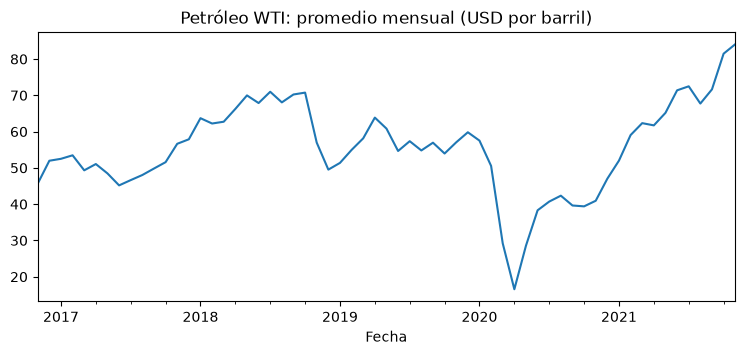

In [27]:
# Remuestreo: del precio diario al promedio mensual
mensual = df['DCOILWTICO'].resample('ME').mean()
print(mensual.head(3))
mensual.plot(figsize=(9, 3.5), title="Petróleo WTI: promedio mensual (USD por barril)")
plt.xlabel("Fecha")
plt.show()

**Referencia:** PDF parte 1, pág. 112 (el remuestreo y las selecciones por año o mes son ampliación).

## 9. Series de frecuencia específica: `date_range` y `period_range`

### `pd.date_range`

Los datos de series temporales pueden crearse en un intervalo concreto, es decir, con una **frecuencia** específica. `pandas.date_range(start=None, end=None, periods=None, freq=None, tz=None, normalize=False, name=None, ...)` funciona de modo similar a `range()` de Python: devuelve un `DatetimeIndex`. Sus parámetros: `start` (inicio), `end` (fin), `periods` (cantidad de marcas de tiempo) y `freq` (frecuencia; por defecto, un día).

Frecuencias representativas del PDF (pág. 114):

| Alias del PDF | Significado |
|---|---|
| `D` | días naturales |
| `B` | días laborables |
| `W` | semanal |
| `M` | fin de mes |
| `MS` (el PDF escribe `Ms`) | inicio de mes |
| `Q` | trimestral |

**Nota sobre el PDF:** pandas 3 eliminó los alias antiguos. Ya no existen `M` y `Q` para `date_range`; ahora son `ME` (fin de mes) y `QE` (fin de trimestre). Los alias de año `A`/`Y` pasaron a `YE`, y `H` pasó a `h`. Además, el alias del PDF `Ms` **no** es inicio de mes: se escribe `MS`, en mayúsculas. Hay que respetar mayúsculas y minúsculas.

In [28]:
# Ejemplo del PDF: 5 marcas de tiempo diarias
pd.date_range(start='2021-01-01', end=None, periods=5, freq='D', tz=None)

DatetimeIndex(['2021-01-01', '2021-01-02', '2021-01-03', '2021-01-04',
               '2021-01-05'],
              dtype='datetime64[us]', freq='D')

In [29]:
# Con inicio, fin y periods, y sin freq, pandas reparte las 5 marcas a intervalos iguales; aquí con zona horaria Seúl
pd.date_range(start='2021-01-01', end='2021-12-31', periods=5, freq=None, tz='Asia/Seoul')

DatetimeIndex(['2021-01-01 00:00:00+09:00', '2021-04-02 00:00:00+09:00',
               '2021-07-02 00:00:00+09:00', '2021-10-01 00:00:00+09:00',
               '2021-12-31 00:00:00+09:00'],
              dtype='datetime64[us, Asia/Seoul]', freq=None)

In [30]:
# El PDF usa freq='M' (fin de mes). En pandas 3 el alias válido es 'ME'.
pd.date_range(start='2021-01-01', end=None, periods=5, freq='ME', tz=None)

DatetimeIndex(['2021-01-31', '2021-02-28', '2021-03-31', '2021-04-30',
               '2021-05-31'],
              dtype='datetime64[us]', freq='ME')

In [31]:
# Ejemplos de frecuencias vigentes en pandas 3
for f in ['D', 'B', 'W', 'ME', 'MS', 'QE', 'YE', 'h']:
    print(f"{f:>2}", pd.date_range('2021-01-01', periods=3, freq=f).strftime('%Y-%m-%d %H:%M').tolist())

 D ['2021-01-01 00:00', '2021-01-02 00:00', '2021-01-03 00:00']
 B ['2021-01-01 00:00', '2021-01-04 00:00', '2021-01-05 00:00']
 W ['2021-01-03 00:00', '2021-01-10 00:00', '2021-01-17 00:00']
ME ['2021-01-31 00:00', '2021-02-28 00:00', '2021-03-31 00:00']
MS ['2021-01-01 00:00', '2021-02-01 00:00', '2021-03-01 00:00']
QE ['2021-03-31 00:00', '2021-06-30 00:00', '2021-09-30 00:00']
YE ['2021-12-31 00:00', '2022-12-31 00:00', '2023-12-31 00:00']
 h ['2021-01-01 00:00', '2021-01-01 01:00', '2021-01-01 02:00']


In [32]:
# Qué ocurre con un alias antiguo: se captura el error para ver el mensaje
try:
    pd.date_range(start='2021-01-01', periods=5, freq='M')
except ValueError as error:
    print("ValueError:", str(error)[:110], "...")

ValueError: Invalid frequency: M. Failed to parse with error message: ValueError("'M' is no longer supported for offsets.  ...


**Nota sobre el PDF:** la diapositiva 118 muestra `freq='Ms'` y una salida con milisegundos (`freq='L'`): en pandas antiguos `ms`/`Ms` se interpretaba como milisegundos, de modo que el resultado no era inicio de mes aunque el comentario lo dijera. Lo correcto para inicio de mes es `MS`:

In [33]:
# Inicio de mes: MS en mayúsculas
pd.date_range(start='2021-01-01', end=None, periods=5, freq='MS', tz=None)

DatetimeIndex(['2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01',
               '2021-05-01'],
              dtype='datetime64[us]', freq='MS')

### `pd.period_range`

`pandas.period_range(start=None, end=None, periods=None, freq=None, name=None)` crea datos con múltiples periodos y devuelve un `PeriodIndex` (pág. 119). Sus parámetros: inicio del intervalo, fin del intervalo, número de frecuencias a generar y duración del periodo.

In [34]:
p_data = pd.period_range(start='2020-1-1',
                         end='2020-12-31',
                         periods=None,
                         freq='M')

p_data

PeriodIndex(['2020-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06',
             '2020-07', '2020-08', '2020-09', '2020-10', '2020-11', '2020-12'],
            dtype='period[M]')

In [35]:
# Cada periodo conoce cuándo empieza y termina realmente el mes
for i in p_data:
    print("{0} {1}".format(i.start_time, i.end_time))

2020-01-01 00:00:00 2020-01-31 23:59:59.999999
2020-02-01 00:00:00 2020-02-29 23:59:59.999999
2020-03-01 00:00:00 2020-03-31 23:59:59.999999
2020-04-01 00:00:00 2020-04-30 23:59:59.999999
2020-05-01 00:00:00 2020-05-31 23:59:59.999999
2020-06-01 00:00:00 2020-06-30 23:59:59.999999
2020-07-01 00:00:00 2020-07-31 23:59:59.999999
2020-08-01 00:00:00 2020-08-31 23:59:59.999999
2020-09-01 00:00:00 2020-09-30 23:59:59.999999
2020-10-01 00:00:00 2020-10-31 23:59:59.999999
2020-11-01 00:00:00 2020-11-30 23:59:59.999999
2020-12-01 00:00:00 2020-12-31 23:59:59.999999


**Nota sobre el PDF:** en el PDF los mismos datos se muestran en tres diapositivas con comentarios distintos (líneas 3 y 4: inicio y fin; líneas 5 y 6: cantidad y duración; línea 8: la etiqueta del índice es un punto). Las salidas del bucle terminan en `.999999999` en el PDF y en `.999999` con pandas 3, por la resolución de microsegundos.

**Ampliación (no está en el PDF):** la conversión entre ambos tipos se hace con `to_period()` y `to_timestamp()`.

In [36]:
marcas = pd.date_range('2021-01-31', periods=3, freq='ME')
print(marcas.to_period('M'))                    # DatetimeIndex -> PeriodIndex
print(pd.period_range('2021-01', periods=3, freq='M').to_timestamp())   # PeriodIndex -> DatetimeIndex

PeriodIndex(['2021-01', '2021-02', '2021-03'], dtype='period[M]')
DatetimeIndex(['2021-01-01', '2021-02-01', '2021-03-01'],
              dtype='datetime64[us]', freq='MS')


**Clave:** `date_range` devuelve `Timestamp` (puntos); `period_range` devuelve `Period` (tramos con inicio y fin).

**Error común:** usar los alias del PDF (`M`, `Q`, `H`, `A`) en pandas 3. Falla con `ValueError: Invalid frequency`. Hay que usar `ME`, `QE`, `h`, `YE`.

**Para el quiz:** con `freq='B'` solo se generan días laborables; `periods` indica cuántas marcas se crean.

**Referencia:** PDF parte 1, págs. 113–122

## 10. Estadística móvil: la media móvil con `rolling()`

Pandas calcula con facilidad estadísticas móviles (*rolling window*) sobre `DataFrame` y `Series`. Una **ventana** es un periodo o sección que se desplaza automáticamente a lo largo de la serie; en cada posición se calcula la estadística y el resultado se aplica a toda la serie.

La **media móvil** es el método más usado en el análisis financiero para **suavizar** la volatilidad a corto plazo y observar la tendencia a largo plazo. Suavizar significa eliminar las pequeñas fluctuaciones o discontinuidades producidas por el ruido al muestrear.

Métodos representativos (pág. 125), disponibles en `DataFrame.rolling()` y `Series.rolling()`:

| Método | Resultado |
|---|---|
| `.rolling().mean()` | media en la ventana |
| `.rolling().std()` | desviación estándar en la ventana |
| `.rolling().var()` | varianza en la ventana |
| `.rolling().sum()` | suma en la ventana |
| `.rolling().min()` | valor mínimo en la ventana |
| `.rolling().max()` | valor máximo en la ventana |

### Ejemplo del PDF: la acción de Samsung Electronics

El PDF (págs. 127–134) descarga con `pandas_datareader` los precios del ticker `005930.KS` (Samsung Electronics en la bolsa de Corea) de Yahoo Finanzas para todo 2020:

```python
import pandas_datareader.data as web
start = datetime(2020, 1, 1)
end = datetime(2020, 12, 31)
sec = web.DataReader("005930.KS", 'yahoo', start, end)
```

**Nota sobre el PDF:** `pandas_datareader` no está instalado en este entorno y su acceso a Yahoo suele fallar, además de requerir conexión. Se descargaron los precios diarios de 2020 de `005930.KS` desde Yahoo Finanzas y se guardaron en `u38-samsung-005930-2020.csv` (248 filas, como en el PDF). Se lee con `read_csv` indicando la columna `Date` como índice de fechas.

In [37]:
sec = pd.read_csv("../datos/u38-samsung-005930-2020.csv", index_col="Date", parse_dates=True)
sec.head()

,High,Low,Open,Close,Volume,Adj Close
Date,,,,,,
2020-01-02,56000.0,55000.0,55500.0,55200.0,12993228,47320.660156
2020-01-03,56600.0,54900.0,56000.0,55500.0,15422255,47577.851562
2020-01-06,55600.0,54600.0,54900.0,55500.0,10278951,47577.851562
2020-01-07,56400.0,55600.0,55700.0,55800.0,10009778,47835.019531
2020-01-08,57400.0,55900.0,56200.0,56800.0,23501171,48692.285156


In [38]:
# El conjunto ya está indexado por DatetimeIndex
sec.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 248 entries, 2020-01-02 to 2020-12-30
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   High       248 non-null    float64
 1   Low        248 non-null    float64
 2   Open       248 non-null    float64
 3   Close      248 non-null    float64
 4   Volume     248 non-null    int64  
 5   Adj Close  248 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 13.6 KB


**Nota sobre el PDF:** `Adj Close` (precio ajustado) se recalcula con los dividendos y divisiones posteriores, así que los valores de hoy no coinciden con los del PDF (por ejemplo, la media de 5 días del 2020-01-08 era 52 586 en el PDF). La estructura y la forma de las curvas son las mismas.

In [39]:
# Media móvil de 5 días: las primeras 4 filas son NaN porque la ventana aún no tiene 5 datos
ma5 = sec['Adj Close'].rolling(window=5).mean()
ma5.head(10)

Date
2020-01-02             NaN
2020-01-03             NaN
2020-01-06             NaN
2020-01-07             NaN
2020-01-08    47800.733594
2020-01-09    48383.668750
2020-01-10    49069.472656
2020-01-13    49841.002344
2020-01-14    50561.098437
2020-01-15    50938.291406
Name: Adj Close, dtype: float64

In [40]:
# Con min_periods se pueden calcular las primeras posiciones con una ventana incompleta (ampliación)
print(sec['Adj Close'].rolling(window=5, min_periods=1).mean().head(5))

Date
2020-01-02    47320.660156
2020-01-03    47449.255859
2020-01-06    47492.121094
2020-01-07    47577.845703
2020-01-08    47800.733594
Name: Adj Close, dtype: float64


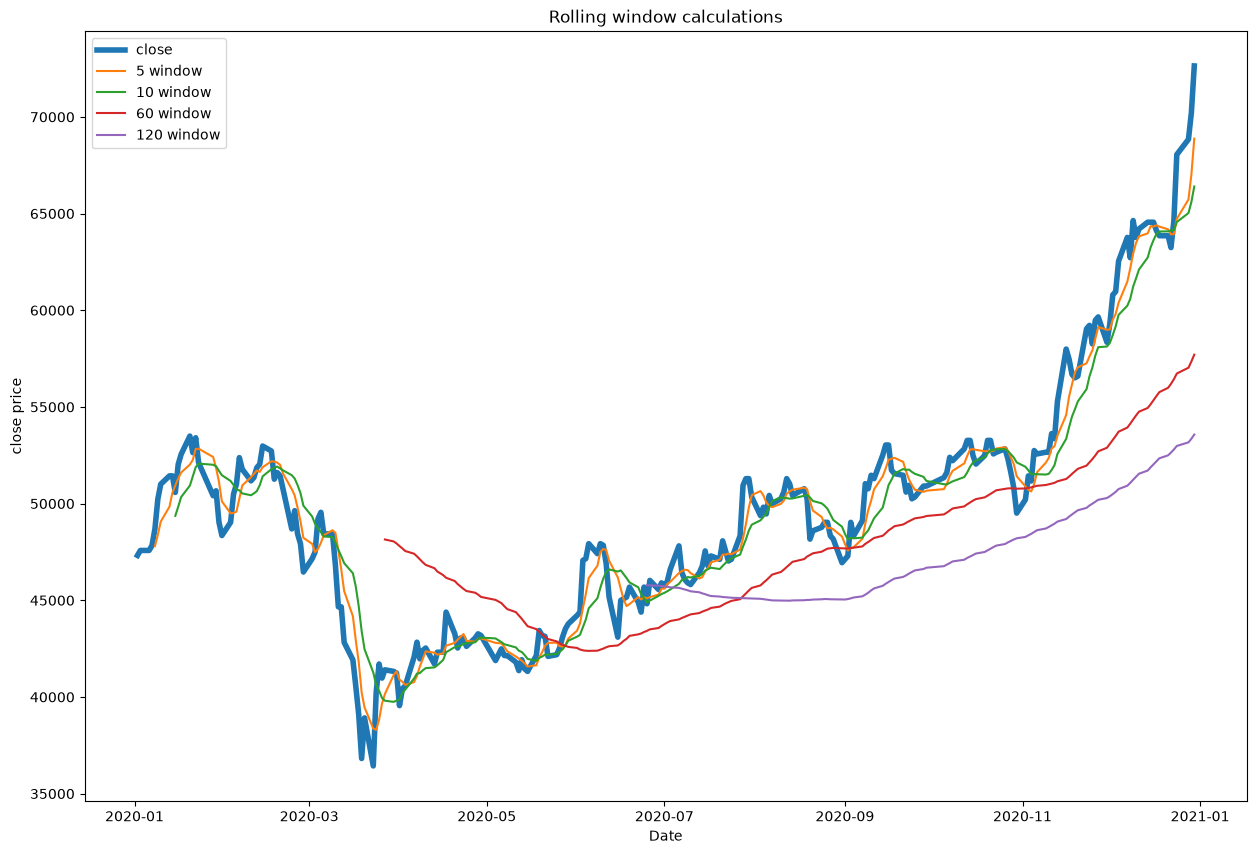

In [41]:
close = sec['Adj Close']

ma5 = sec['Adj Close'].rolling(window=5).mean()
ma10 = sec['Adj Close'].rolling(window=10).mean()
ma60 = sec['Adj Close'].rolling(window=60).mean()
ma120 = sec['Adj Close'].rolling(window=120).mean()

plt.figure(figsize=(15, 10))

plt.plot(close, label='close', linewidth=4)
plt.plot(ma5, label='5 window')
plt.plot(ma10, label='10 window')
plt.plot(ma60, label='60 window')
plt.plot(ma120, label='120 window')

plt.legend()
plt.title('Rolling window calculations')
plt.xlabel('Date')
plt.ylabel('close price')
plt.show()

**Nota sobre el PDF:** en el código de la diapositiva 131 la variable `ma120` se calcula con `window=20`, aunque la etiqueta dice `120 window`. Es un error del PDF; aquí se usa `window=120`, que es lo que indica la etiqueta. Con 20 días la curva sería casi igual de ruidosa que la de 10.

Cómo leer el gráfico: cuanto mayor es la ventana, más suave es la curva y más tarda en reaccionar a los cambios. Con `window=120` la curva empieza recién en el día 120 del año, porque antes no hay suficientes datos.

In [42]:
# Otras estadísticas móviles (ampliación): rango de 20 días y volatilidad
ventana = sec['Adj Close'].rolling(window=20)
resumen = pd.DataFrame({
    'media': ventana.mean(),
    'desviacion': ventana.std(),
    'minimo': ventana.min(),
    'maximo': ventana.max(),
})
resumen.dropna().head()

,media,desviacion,minimo,maximo
Date,,,,
2020-01-31,50419.651758,2019.329128,47320.660156,53492.921875
2020-02-03,50505.377344,1914.517536,47577.851562,53492.921875
2020-02-04,50651.110352,1786.604640,47577.851562,53492.921875
2020-02-05,50822.561328,1634.189063,47835.019531,53492.921875
2020-02-06,51049.734570,1507.948081,48349.375000,53492.921875


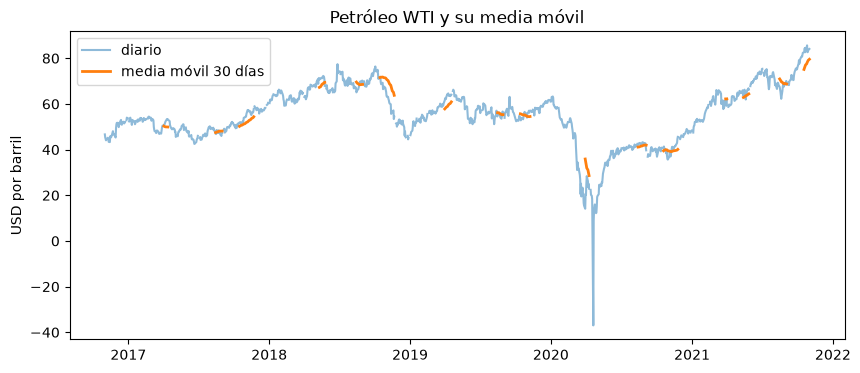

In [43]:
# La misma idea aplicada al petróleo WTI de la sección 7 (ampliación): media móvil de 30 días
wti_ma30 = df['DCOILWTICO'].rolling(window=30).mean()
plt.figure(figsize=(10, 4))
plt.plot(df['DCOILWTICO'], label='diario', alpha=0.5)
plt.plot(wti_ma30, label='media móvil 30 días', linewidth=2)
plt.legend()
plt.title('Petróleo WTI y su media móvil')
plt.ylabel('USD por barril')
plt.show()

**Clave:** `serie.rolling(window=N).mean()` promedia las últimas `N` observaciones. Las primeras `N-1` posiciones son `NaN`.

**Error común:** creer que la media móvil de 120 días muestra todo el año; empieza con retraso porque necesita 120 datos.

**Para el quiz:** la media móvil suaviza la volatilidad a corto plazo y muestra la tendencia; es la estadística descriptiva representativa de las series temporales.

**Referencia:** PDF parte 1, págs. 123–134

## Proyecto de la unidad: producción mundial de marisco

**Problema (págs. 78–80).** En el negocio mundial del marisco, ¿la mayor parte del pescado se captura o se cría en acuicultura? Hay que usar los datos de Our World in Data (`ourworldindata.org/fish-and-overfishing`, descargados el 6 de noviembre de 2021) y, además, buscar países concretos y crear sus estadísticas por separado. Las tareas:

1. Convertir el archivo CSV en un marco de datos.
2. Eliminar columnas innecesarias.
3. Convertir los datos del año a serie temporal y usarlos como índice.
4. Transformar los datos de los países en datos categóricos.
5. Comprobar si existen datos `NaN` y sustituirlos.
6. Visualizar las tendencias de acuicultura y capturas directas del mundo desde la década de 1960.
7. Buscar 3 o más países individuales y compararlos con gráficos.

El resultado esperado es un gráfico como el de la pág. 80 (fuente original: FAO vía Banco Mundial): dos curvas: la captura silvestre, que crece hasta mediados de la década de 1990 y luego se estabiliza, y la acuicultura, que sube sin parar hasta superar a la captura hacia 2013–2015.

**Nota sobre el PDF:** el archivo del PDF (`captura-pesca-vs-acuicultura.csv`, 14 674 filas, hasta 2018) no se incluye. Se descargó la versión actual del mismo gráfico de Our World in Data y se renombraron las columnas para que coincidan con las del PDF (`Aquaculture production (metric tons)` y `Capture fisheries production (metric tons)`). Se recortó a los años hasta 2018 (12 385 filas, 229 entidades) para parecerse al archivo del PDF. Por ser una versión revisada, algunas cifras difieren, y el archivo actual no trae datos faltantes en estas dos columnas, mientras que el del PDF sí (3017 y 158 `NaN`).

### Paso 1. Adquisición de datos y transformación a marco de datos

In [44]:
df = pd.read_csv("../datos/u38-captura-pesca-vs-acuicultura.csv")
df.head()

,Entity,Code,Year,Aquaculture production (metric tons),Capture fisheries production (metric tons)
0,Afghanistan,AFG,1960,0.0,200.0
1,Afghanistan,AFG,1961,0.0,300.0
2,Afghanistan,AFG,1962,0.0,300.0
3,Afghanistan,AFG,1963,0.0,300.0
4,Afghanistan,AFG,1964,0.0,300.0


In [45]:
# Tipo de datos de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12385 entries, 0 to 12384
Data columns (total 5 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Entity                                      12385 non-null  str    
 1   Code                                        12385 non-null  str    
 2   Year                                        12385 non-null  int64  
 3   Aquaculture production (metric tons)        12385 non-null  float64
 4   Capture fisheries production (metric tons)  12385 non-null  float64
dtypes: float64(2), int64(1), str(2)
memory usage: 483.9 KB


### Paso 2. Preprocesamiento y limpieza

**2a. Eliminar columnas innecesarias.** El código del país no se necesita para las estadísticas.

In [46]:
df = df.drop(['Code'], axis=1)
df.head()

,Entity,Year,Aquaculture production (metric tons),Capture fisheries production (metric tons)
0,Afghanistan,1960,0.0,200.0
1,Afghanistan,1961,0.0,300.0
2,Afghanistan,1962,0.0,300.0
3,Afghanistan,1963,0.0,300.0
4,Afghanistan,1964,0.0,300.0


**2b. Buscar datos `NaN` y sustituirlos.** Se sustituyen por 0 para no afectar la estadística de la suma (pág. 140).

In [47]:
# Buscar datos NaN. Puede comprobar el número de datos que faltan para cada columna.
df.isnull().sum()

Entity                                        0
Year                                          0
Aquaculture production (metric tons)          0
Capture fisheries production (metric tons)    0
dtype: int64

In [48]:
change_value = 0
df = df.fillna(change_value)
df.isnull().sum()

Entity                                        0
Year                                          0
Aquaculture production (metric tons)          0
Capture fisheries production (metric tons)    0
dtype: int64

**Nota sobre el PDF:** el PDF usa `inplace=True` en `drop`, `fillna` y `set_index`. Pandas 3.1 avisa que ese argumento está en desuso (PDEP-8), así que aquí se reasigna el resultado (`df = df.drop(...)`), que hace lo mismo. Con los datos del PDF había 3017 faltantes de acuicultura y 158 de captura; con el archivo actual no hay ninguno y las dos celdas imprimen ceros. El código es el mismo y sigue siendo la forma de resolverlo cuando existan faltantes.

**Error común:** sustituir por 0 un dato faltante equivale a afirmar que la producción fue nula. Para una suma es aceptable; para un promedio distorsiona el resultado.

**2c. Cambio a tipo de series temporales y sustitución del índice.** `Year` es un entero (`int64`). Convertirlo directamente a `datetime` lo interpretaría como nanosegundos desde 1970, no como años, por eso el PDF lo pasa primero a texto y le da un formato `%Y` (pág. 141).

In [49]:
df['new_Year'] = pd.to_datetime(df['Year'].astype(str), format='%Y')
df = df.set_index('new_Year')
df = df.drop(['Year'], axis=1)

df.head()

,Entity,Aquaculture production (metric tons),Capture fisheries production (metric tons)
new_Year,,,
1960-01-01,Afghanistan,0.0,200.0
1961-01-01,Afghanistan,0.0,300.0
1962-01-01,Afghanistan,0.0,300.0
1963-01-01,Afghanistan,0.0,300.0
1964-01-01,Afghanistan,0.0,300.0


In [50]:
# Se confirma que el índice ahora es un DatetimeIndex
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 12385 entries, 1960-01-01 to 2018-01-01
Data columns (total 3 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Entity                                      12385 non-null  str    
 1   Aquaculture production (metric tons)        12385 non-null  float64
 2   Capture fisheries production (metric tons)  12385 non-null  float64
dtypes: float64(2), str(1)
memory usage: 387.0 KB


In [51]:
# Ordenación del marco de datos según el índice de fechas
new_df = df.sort_index()
new_df.head()

,Entity,Aquaculture production (metric tons),Capture fisheries production (metric tons)
new_Year,,,
1960-01-01,Afghanistan,0.0,200.0
1960-01-01,Benin,0.0,26000.0
1960-01-01,Norway,1900.0,1609362.0
1960-01-01,Oman,0.0,55000.0
1960-01-01,Pakistan,1170.0,76047.0


**Error común:** `pd.to_datetime(df['Year'])` con enteros como `1969` produce `1970-01-01 00:00:00.000001969`; el PDF lo evita con `astype(str)` y `format='%Y'`.

**2d. Datos categóricos.** El nombre de país se repite miles de veces. Convertirlo a tipo `category` ahorra memoria y deja claro que son etiquetas de un conjunto finito (pág. 145).

In [52]:
new_df['Entity'] = new_df['Entity'].astype('category')
new_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 12385 entries, 1960-01-01 to 2018-01-01
Data columns (total 3 columns):
 #   Column                                      Non-Null Count  Dtype   
---  ------                                      --------------  -----   
 0   Entity                                      12385 non-null  category
 1   Aquaculture production (metric tons)        12385 non-null  float64 
 2   Capture fisheries production (metric tons)  12385 non-null  float64 
dtypes: category(1), float64(2)
memory usage: 316.3 KB


### Paso 3. Explorar y agrupar

Cuántos datos hay por cada entidad (el PDF cuenta 264 entidades; en el archivo actual hay 229):

In [53]:
new_df['Entity'].value_counts()

Entity
Afghanistan                   59
Albania                       59
Algeria                       59
American Samoa                59
Angola                        59
                              ..
Saint Martin (French part)    12
Curacao                        8
Sint Maarten (Dutch part)      8
South Sudan                    7
Sudan                          7
Name: count, Length: 229, dtype: int64

Hay datos separados por país y por año. Para ver la tendencia mundial hay que calcular la **suma del mundo** (la suma de los países) de cada año, agrupando por el año. Se agrupa por el índice `new_Year` y se guarda el agrupador en `g` (pág. 147).

In [54]:
g = new_df.groupby(['new_Year'])
g.head()

,Entity,Aquaculture production (metric tons),Capture fisheries production (metric tons)
new_Year,,,
1960-01-01,Afghanistan,0.0,200.00
1960-01-01,Benin,0.0,26000.00
1960-01-01,Norway,1900.0,1609362.00
1960-01-01,Oman,0.0,55000.00
1960-01-01,Pakistan,1170.0,76047.00
...,...,...,...
2018-01-01,Senegal,1108.0,484654.66
2018-01-01,Cayman Islands,10.0,125.00
2018-01-01,Syria,2225.0,4074.00


In [55]:
# Recorrer el objeto g con un bucle (se muestran solo los dos primeros grupos)
for key, group in g:
    print('+key:', key)
    print('+number:', len(group))
    print(group.head(3))
    print('\n')
    if key[0] >= pd.Timestamp('1961-01-01'):
        break

+key: (Timestamp('1960-01-01 00:00:00'),)
+number: 192
                 Entity  Aquaculture production (metric tons)  \
new_Year                                                        
1960-01-01  Afghanistan                                   0.0   
1960-01-01        Benin                                   0.0   
1960-01-01       Norway                                1900.0   

            Capture fisheries production (metric tons)  
new_Year                                                
1960-01-01                                       200.0  
1960-01-01                                     26000.0  
1960-01-01                                   1609362.0  


+key: (Timestamp('1961-01-01 00:00:00'),)
+number: 193
                         Entity  Aquaculture production (metric tons)  \
new_Year                                                                
1961-01-01              Iceland                                   0.0   
1961-01-01  Antigua and Barbuda                           

**Nota sobre el PDF:** el PDF imprime el bucle completo de grupos. Aquí se corta después de dos para no llenar el cuaderno. Con pandas 3, iterar un `groupby` con una lista de una columna (`['new_Year']`) entrega la clave como tupla de un elemento, por eso el código usa `key[0]`.

### Paso 4. Suma mundial y visualización

In [56]:
world_total = g.sum(numeric_only=True)
world_total.head()

,Aquaculture production (metric tons),Capture fisheries production (metric tons)
new_Year,,
1960-01-01,8514057.0,132867178.0
1961-01-01,8189975.0,147655827.0
1962-01-01,8537015.0,160164591.0
1963-01-01,9539332.0,162767759.1
1964-01-01,10312484.0,179846469.1


**Nota sobre el PDF:** el PDF escribe `g.sum()` y obtiene solo las dos columnas numéricas. Con pandas 3, `sum()` intenta sumar también la columna `Entity` (categórica) y falla, por eso se usa `numeric_only=True`.

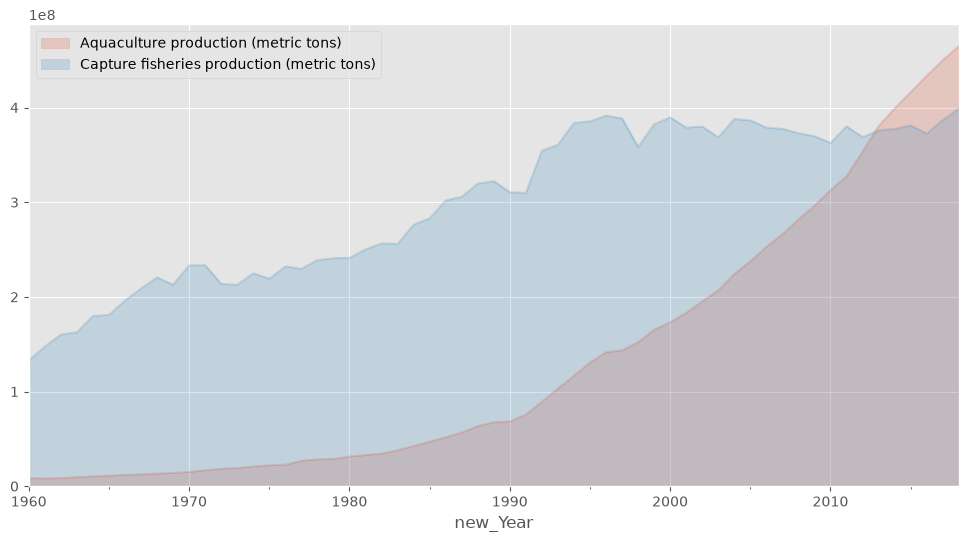

In [57]:
plt.style.use('ggplot')
world_total.plot(kind='area',
                 alpha=0.2,
                 stacked=False,
                 figsize=(12, 6))

plt.legend()
plt.show()

En el PDF el gráfico se dibuja en tamaño `(20, 10)` con la leyenda sin etiquetas de ejes; aquí se redujo el tamaño por comodidad de lectura. `kind='area'` colorea el área bajo cada línea, `alpha=0.2` regula la transparencia para ver las capas superpuestas y `stacked=False` hace que las áreas se superpongan en lugar de apilarse.

**Error del método del PDF.** La entidad no es solo un país: el archivo incluye también regiones y grupos de ingresos (`World`, `North America`, `Middle income`, `Middle East & North Africa (IDA & IBRD)`...). Sumar todas las filas cuenta la misma producción varias veces. Se puede comprobar comparando con la fila `World`:

In [58]:
anio = pd.Timestamp('2018-01-01')
print("Suma de todas las entidades:", world_total.loc[anio].to_dict())
mundo = new_df[new_df['Entity'] == 'World']
print("Fila 'World' del archivo:   ", mundo.loc[anio].drop('Entity').to_dict())

Suma de todas las entidades: {'Aquaculture production (metric tons)': 464860003.95199996, 'Capture fisheries production (metric tons)': 398879460.866}
Fila 'World' del archivo:    {'Aquaculture production (metric tons)': 116022424.0, 'Capture fisheries production (metric tons)': 98740430.0}


**Nota sobre el PDF:** la suma del PDF sobreestima el total mundial porque suma entidades que ya son agregados. La tendencia general se parece, pero las cifras no son correctas. La versión adecuada usa la fila `World` (o filtra solo los países reales). Como el código `OWID_*` ya se eliminó en el paso 2, el filtro más simple es `Entity == 'World'`:

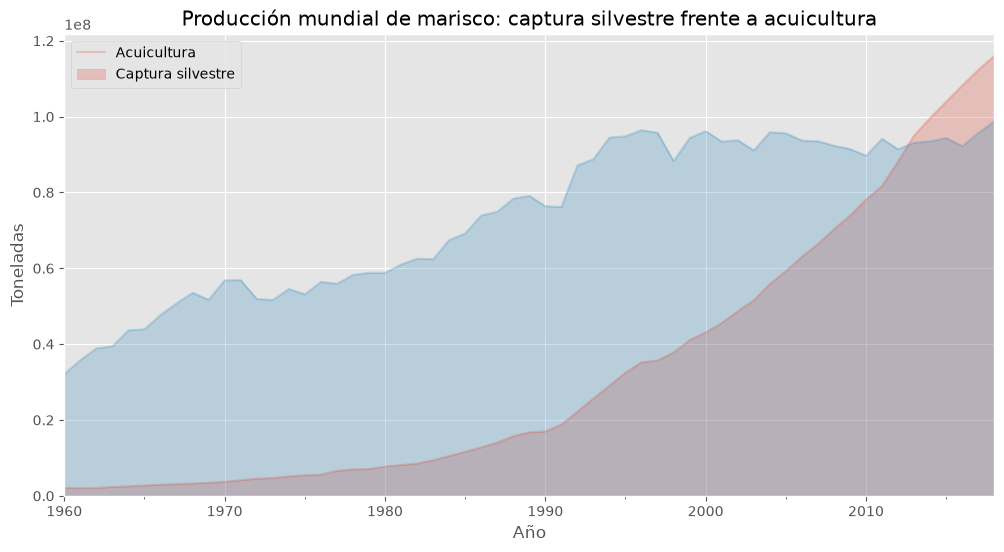

Primer año en que la acuicultura supera a la captura: 2013


In [59]:
mundo = new_df[new_df['Entity'] == 'World'].drop(columns='Entity')

mundo.plot(kind='area', alpha=0.25, stacked=False, figsize=(12, 6))
plt.title('Producción mundial de marisco: captura silvestre frente a acuicultura')
plt.xlabel('Año')
plt.ylabel('Toneladas')
plt.legend(['Acuicultura', 'Captura silvestre'])
plt.show()

cruce = mundo[mundo.iloc[:, 0] > mundo.iloc[:, 1]].index.min()
print("Primer año en que la acuicultura supera a la captura:", cruce.year)

**Resultado:** la captura silvestre pasa de unos 32 millones de toneladas en 1960 a más de 90 millones en la segunda mitad de los años noventa y luego se mantiene entre 90 y 99 millones, mientras que la acuicultura sube sin parar y supera a la captura en 2013 (el código lo calcula). Es el mismo patrón del gráfico de la pág. 80. La conclusión del PDF (pág. 152) es que el mundo ha ido aumentando la cantidad de acuicultura en lugar de la captura.

### Paso 5. Comparar países

Se busca un país en la columna `Entity`: `value_counts()` devuelve una serie cuyo índice son los nombres sin repetir, y la expresión `'South Korea' in country` consulta ese índice (págs. 153–154).

In [60]:
country = new_df['Entity'].value_counts()
print(country.head())
print("Data type =>", type(country))

Entity
Afghanistan       59
Albania           59
Algeria           59
American Samoa    59
Angola            59
Name: count, dtype: int64
Data type => <class 'pandas.Series'>


In [61]:
'South Korea' in country

True

In [62]:
# Un marco de datos por país
s = new_df.loc[new_df['Entity'] == 'South Korea']
c = new_df.loc[new_df['Entity'] == 'China']
a = new_df.loc[new_df['Entity'] == 'Afghanistan']

s_y = s[['Aquaculture production (metric tons)', 'Capture fisheries production (metric tons)']]
s_x = s.index

c_y = c[['Aquaculture production (metric tons)', 'Capture fisheries production (metric tons)']]
c_x = c.index

a_y = a[['Aquaculture production (metric tons)', 'Capture fisheries production (metric tons)']]
a_x = a.index

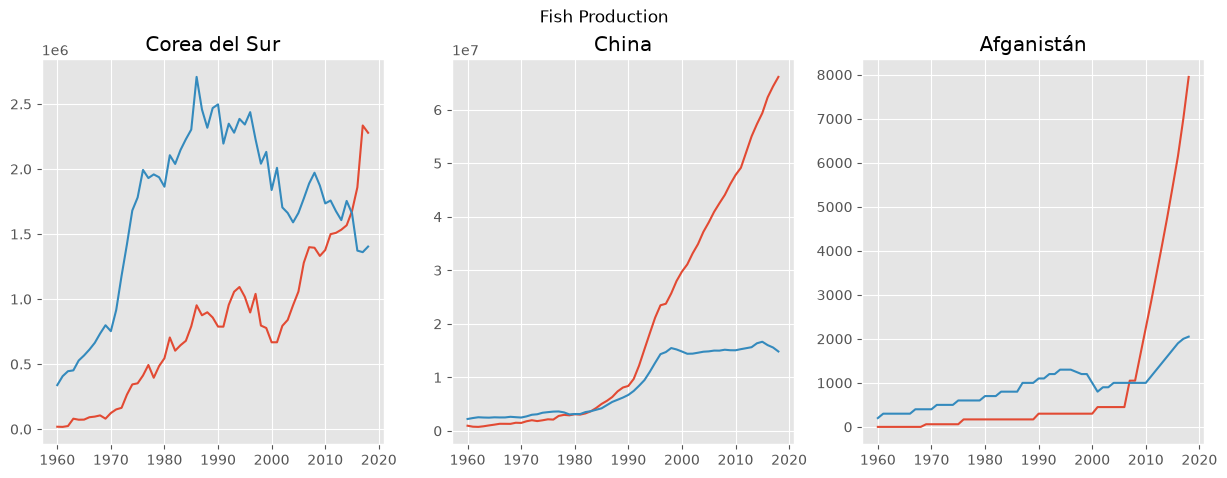

In [63]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].plot(s_x, s_y)
axs[1].plot(c_x, c_y)
axs[2].plot(a_x, a_y)

fig.suptitle('Fish Production')
for eje, nombre in zip(axs, ['Corea del Sur', 'China', 'Afganistán']):
    eje.set_title(nombre)
plt.show()

**Nota sobre el PDF:** el gráfico del PDF no incluye leyenda ni títulos por panel, así que no se sabe qué línea es cuál (el orden de colores depende del orden de las columnas). Aquí se añade un título por panel. Una versión con leyenda explícita, sobre tres países de contextos distintos:

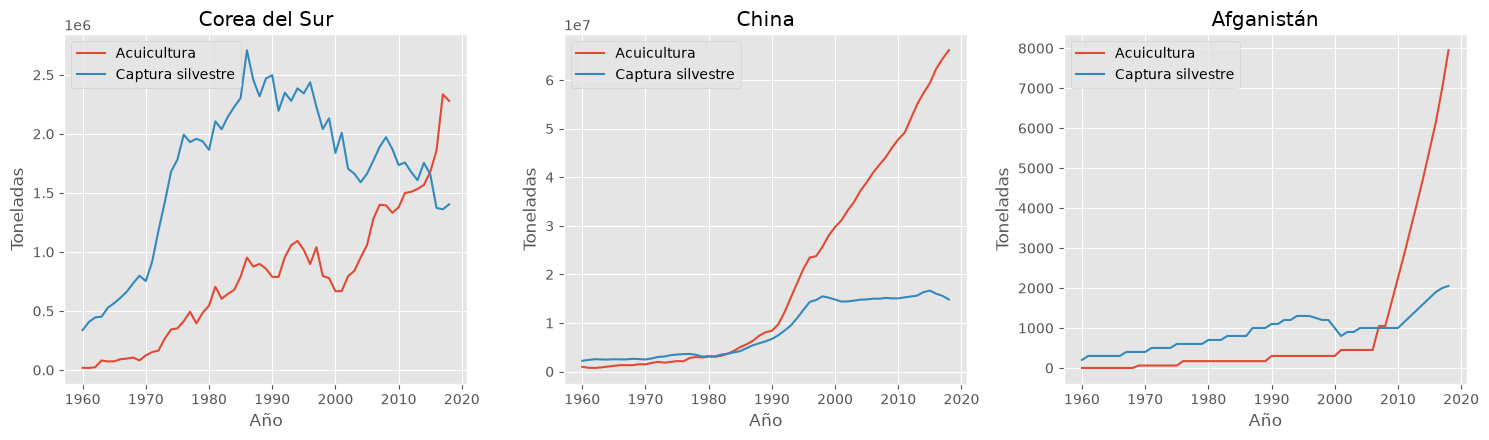

In [64]:
paises = ['South Korea', 'China', 'Afghanistan']
nombres = {'South Korea': 'Corea del Sur', 'China': 'China', 'Afghanistan': 'Afganistán'}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for eje, pais in zip(axs, paises):
    datos = new_df[new_df['Entity'] == pais].drop(columns='Entity')
    eje.plot(datos.index, datos.iloc[:, 0], label='Acuicultura')
    eje.plot(datos.index, datos.iloc[:, 1], label='Captura silvestre')
    eje.set_title(nombres[pais])
    eje.set_xlabel('Año')
    eje.set_ylabel('Toneladas')
    eje.legend()
plt.tight_layout()
plt.show()

**Lectura:** en China la acuicultura despega desde la década de 1980 y en 2018 es unas cuatro veces la captura (66 frente a 15 millones de toneladas); en Corea del Sur la captura alcanza su máximo hacia 1990 (2,5 millones) y baja a 1,4 millones en 2018, mientras la acuicultura sube a 2,3 millones; Afganistán, sin costa, produce apenas miles de toneladas y la acuicultura supera a la captura solo en los últimos años. Las diferencias de escala justifican graficar cada país en su propio eje.

**Ampliación (no está en el PDF):** el remuestreo de series anuales a periodos de cinco años con `resample('5YE')` suaviza las cifras:

In [65]:
corea = new_df[new_df['Entity'] == 'South Korea'].drop(columns='Entity')
corea.resample('5YE').mean().round(0).tail()

,Aquaculture production (metric tons),Capture fisheries production (metric tons)
new_Year,,
2000-12-31,835895.0,2135272.0
2005-12-31,862558.0,1725768.0
2010-12-31,1356402.0,1848324.0
2015-12-31,1557187.0,1691096.0
2020-12-31,2157556.0,1379143.0


**Referencia:** PDF parte 1, págs. 136–157

## Programación en pareja

El PDF (págs. 159–162) incluye dos actividades para hacer con un compañero. Antes, dos diapositivas explican cómo trabajar en pareja: preparar pautas y planes de contingencia (turnarse el ratón, qué hacer si uno falta), emparejar habilidades similares aunque no iguales, ofrecer incentivos, evitar trampas definiendo qué conductas se consideran tales, y crear un entorno de aprendizaje colaborativo, donde se trabaja junto y no se divide el trabajo.

**Actividad Q1.** Discutir y practicar con la compañera o el compañero los datos de la sección de conceptos clave: cambiarlos por los datos de **otra empresa** y probar a **dividirlos en función de la fecha**.

Se descargó otra empresa coreana de la misma bolsa para repetir el análisis: SK hynix (`000660.KS`), 2020.

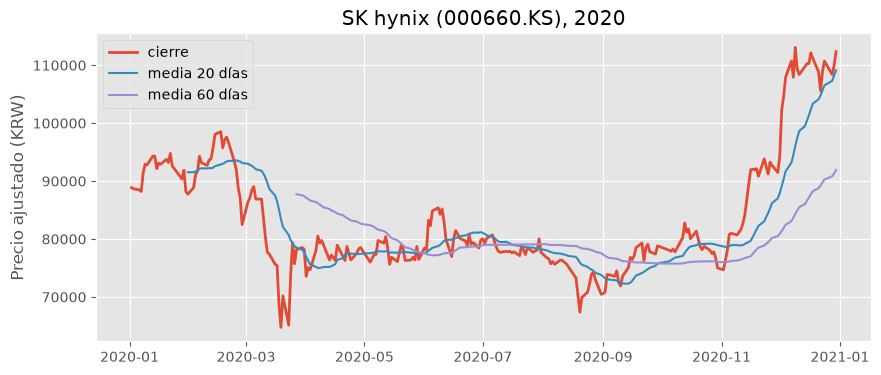

In [66]:
hynix = pd.read_csv("../datos/u38-sk-hynix-000660-2020.csv", index_col="Date", parse_dates=True)

# Media móvil de 20 y 60 días, igual que con Samsung
plt.figure(figsize=(10, 4))
plt.plot(hynix['Adj Close'], label='cierre', linewidth=2)
plt.plot(hynix['Adj Close'].rolling(20).mean(), label='media 20 días')
plt.plot(hynix['Adj Close'].rolling(60).mean(), label='media 60 días')
plt.legend()
plt.title('SK hynix (000660.KS), 2020')
plt.ylabel('Precio ajustado (KRW)')
plt.show()

In [67]:
# Dividir por fecha: primer semestre y segundo semestre (troceado con DatetimeIndex)
s1 = hynix.loc['2020-01':'2020-06', 'Adj Close']
s2 = hynix.loc['2020-07':'2020-12', 'Adj Close']
print("Primer semestre :", len(s1), "días, media", round(s1.mean(), 1))
print("Segundo semestre:", len(s2), "días, media", round(s2.mean(), 1))

# Comparación con Samsung por trimestre (resample)
trimestral = pd.DataFrame({
    'Samsung': sec['Adj Close'].resample('QE').mean(),
    'SK hynix': hynix['Adj Close'].resample('QE').mean(),
}).round(0)
trimestral

Primer semestre : 123 días, media 83110.8
Segundo semestre: 125 días, media 83670.6


,Samsung,SK hynix
Date,,
2020-03-31,47924.0,87424.0
2020-06-30,43607.0,78727.0
2020-09-30,49183.0,76044.0
2020-12-31,57599.0,91672.0


**Actividad Q2.** Entrar al repositorio de la Universidad de California, Irvine (UCI Machine Learning Repository), mencionado en la clase anterior, y explorar con la pareja qué conjuntos de datos aprovechan las ventajas del análisis de series temporales.

El repositorio permite filtrar por tarea de series temporales (*Time Series*). Un ejemplo adecuado es **Air Quality** (calidad del aire): mediciones horarias de sensores en una ciudad italiana de marzo de 2004 a abril de 2005, con fecha y hora en columnas separadas, decimales con coma y el valor `-200` para los datos faltantes.

**Nota sobre el PDF:** el PDF no nombra un conjunto concreto, solo pide explorar el repositorio. Se eligió Air Quality (`archive.ics.uci.edu/dataset/360/air+quality`) como ejemplo. Se descargó y se conservaron 5 de las 15 columnas (`Date`, `Time`, `CO(GT)`, `T`, `RH`) en `u38-uci-calidad-aire.csv` (9270 filas, hasta marzo de 2005). Esta parte es una ampliación de lo pedido y no copia código del PDF.

In [68]:
aire = pd.read_csv("../datos/u38-uci-calidad-aire.csv", sep=";", decimal=",")
print(aire.head(3))

# Fecha y hora vienen separadas, con formato día/mes/año y hora con puntos
aire['marca'] = pd.to_datetime(aire['Date'] + ' ' + aire['Time'], format='%d/%m/%Y %H.%M.%S')
aire = aire.set_index('marca').drop(columns=['Date', 'Time'])

# En este conjunto, -200 significa dato faltante
aire = aire.replace(-200, np.nan)
print(aire.index.min(), aire.index.max(), aire.isna().sum().to_dict())

         Date      Time  CO(GT)     T    RH
0  10/03/2004  18.00.00     2.6  13.6  48.9
1  10/03/2004  19.00.00     2.0  13.3  47.7
2  10/03/2004  20.00.00     2.2  11.9  54.0
2004-03-10 18:00:00 2005-03-31 23:00:00 {'CO(GT)': 1681, 'T': 366, 'RH': 366}


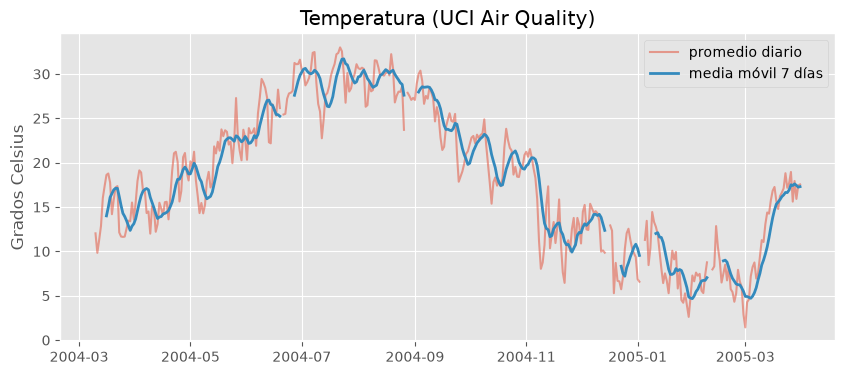

marca
0    16.1
1    15.7
2    15.3
3    14.9
4    14.5
5    14.2
6    14.0
7    14.3
Name: T, dtype: float64

In [69]:
# Promedio diario de temperatura y media móvil de 7 días
temperatura = aire['T'].resample('D').mean()
plt.figure(figsize=(10, 4))
plt.plot(temperatura, alpha=0.5, label='promedio diario')
plt.plot(temperatura.rolling(7).mean(), label='media móvil 7 días', linewidth=2)
plt.legend()
plt.title('Temperatura (UCI Air Quality)')
plt.ylabel('Grados Celsius')
plt.show()

# Patrón estacional dentro del día: promedio por hora
aire.groupby(aire.index.hour)['T'].mean().round(1).head(8)

**Referencia:** PDF parte 1, págs. 158–162

## Práctica

Ejercicios de dificultad creciente sobre `Timestamp`, `Timedelta`, `Period`, `to_datetime`, troceado, remuestreo y medias móviles. Cada función trae su verificación y una solución plegada.

### Ejercicio 1 — Crear una marca de tiempo

Escribe `crear_marca(texto)` que reciba una fecha y hora en texto (por ejemplo `'2021-07-07 15:50'`) y devuelva el `pd.Timestamp` correspondiente.

In [70]:
def crear_marca(texto):
    # Escribe tu solución aquí
    pass

In [71]:
try:
    verificar("fecha y hora", crear_marca('2021-07-07 15:50'), pd.Timestamp(2021, 7, 7, 15, 50))
    verificar("solo fecha", crear_marca('2017-01-15'), pd.Timestamp('2017-01-15 00:00:00'))
    verificar("tipo", type(crear_marca('2020-02-29')).__name__, 'Timestamp')
except (AttributeError, TypeError, KeyError, ValueError) as error:
    print(f"Incorrecto: la función aún no devuelve un resultado válido ({type(error).__name__})")

Incorrecto: fecha y hora. Se esperaba Timestamp('2021-07-07 15:50:00') y se obtuvo None
Incorrecto: solo fecha. Se esperaba Timestamp('2017-01-15 00:00:00') y se obtuvo None
Incorrecto: tipo. Se esperaba 'Timestamp' y se obtuvo 'NoneType'


<details><summary>Ver solución</summary>

```python
def crear_marca(texto):
    return pd.Timestamp(texto)
```

`pd.Timestamp` acepta cadenas y devuelve un `Timestamp`; si no hay hora, queda en 00:00:00.
</details>

### Ejercicio 2 — Días entre dos fechas

Escribe `dias_entre(inicio, fin)` que reciba dos fechas en texto `'AAAA-MM-DD'` y devuelva el número entero de días que hay de la primera a la segunda (puede ser negativo).

In [72]:
def dias_entre(inicio, fin):
    # Escribe tu solución aquí
    pass

In [73]:
try:
    verificar("un mes de enero", dias_entre('2021-01-01', '2021-02-01'), 31)
    verificar("año bisiesto", dias_entre('2020-02-01', '2020-03-01'), 29)
    verificar("orden inverso", dias_entre('2021-03-10', '2021-03-01'), -9)
except (AttributeError, TypeError, KeyError, ValueError) as error:
    print(f"Incorrecto: la función aún no devuelve un resultado válido ({type(error).__name__})")

Incorrecto: un mes de enero. Se esperaba 31 y se obtuvo None
Incorrecto: año bisiesto. Se esperaba 29 y se obtuvo None
Incorrecto: orden inverso. Se esperaba -9 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def dias_entre(inicio, fin):
    return (pd.Timestamp(fin) - pd.Timestamp(inicio)).days
```

La resta de dos `Timestamp` es un `Timedelta`; su atributo `.days` da el número de días enteros.
</details>

### Ejercicio 3 — Desplazar un periodo mensual

Escribe `desplazar_mes(texto, n)` que reciba un mes en texto (`'1973-07'`) y un entero `n`, y devuelva en texto (`str`) el periodo mensual desplazado `n` meses.

In [74]:
def desplazar_mes(texto, n):
    # Escribe tu solución aquí
    pass

In [75]:
try:
    verificar("el ejemplo del PDF", desplazar_mes('1973-07', 2), '1973-09')
    verificar("cruza de año", desplazar_mes('2020-11', 3), '2021-02')
    verificar("hacia atrás", desplazar_mes('2021-01', -1), '2020-12')
except (AttributeError, TypeError, KeyError, ValueError) as error:
    print(f"Incorrecto: la función aún no devuelve un resultado válido ({type(error).__name__})")

Incorrecto: el ejemplo del PDF. Se esperaba '1973-09' y se obtuvo None
Incorrecto: cruza de año. Se esperaba '2021-02' y se obtuvo None
Incorrecto: hacia atrás. Se esperaba '2020-12' y se obtuvo None


<details><summary>Ver solución</summary>

```python
def desplazar_mes(texto, n):
    return str(pd.Period(texto, freq='M') + n)
```

Sumar un entero a un `Period` lo mueve en su propia frecuencia (meses). `str()` da la forma `AAAA-MM`.
</details>

### Ejercicio 4 — Texto a DatetimeIndex

Escribe `indexar_por_fecha(df, columna)` que reciba un `DataFrame` con una columna de fechas en texto y devuelva un nuevo `DataFrame` con esa columna convertida a `datetime64`, usada como índice y ordenada de la fecha más antigua a la más reciente.

In [76]:
def indexar_por_fecha(df, columna):
    # Escribe tu solución aquí
    pass

In [77]:
try:
    datos = pd.DataFrame({'dia': ['2021-03-03', '2021-03-01', '2021-03-02'], 'valor': [30, 10, 20]})
    r = indexar_por_fecha(datos, 'dia')
    verificar("el índice es DatetimeIndex", isinstance(r.index, pd.DatetimeIndex), True)
    verificar("ordenado", r['valor'].tolist(), [10, 20, 30])
    verificar("sin la columna de texto", list(r.columns), ['valor'])
except (AttributeError, TypeError, KeyError, ValueError) as error:
    print(f"Incorrecto: la función aún no devuelve un resultado válido ({type(error).__name__})")

Incorrecto: la función aún no devuelve un resultado válido (AttributeError)


<details><summary>Ver solución</summary>

```python
def indexar_por_fecha(df, columna):
    copia = df.copy()
    copia[columna] = pd.to_datetime(copia[columna])
    return copia.set_index(columna).sort_index()
```

Se convierte con `to_datetime`, se usa como índice con `set_index` (que quita la columna) y se ordena con `sort_index`. La copia evita modificar el marco original.
</details>

### Ejercicio 5 — Contar días en un rango

Escribe `contar_en_rango(serie, inicio, fin)` que reciba una `Series` con `DatetimeIndex` y dos fechas en texto, y devuelva cuántas observaciones hay entre ambas fechas, extremos incluidos.

In [78]:
def contar_en_rango(serie, inicio, fin):
    # Escribe tu solución aquí
    pass

In [79]:
try:
    serie = pd.Series(range(10), index=pd.date_range('2021-01-01', periods=10, freq='D'))
    verificar("rango interior", contar_en_rango(serie, '2021-01-03', '2021-01-06'), 4)
    verificar("un solo día", contar_en_rango(serie, '2021-01-05', '2021-01-05'), 1)
    verificar("rango sin datos", contar_en_rango(serie, '2022-01-01', '2022-01-31'), 0)
except (AttributeError, TypeError, KeyError, ValueError) as error:
    print(f"Incorrecto: la función aún no devuelve un resultado válido ({type(error).__name__})")

Incorrecto: rango interior. Se esperaba 4 y se obtuvo None
Incorrecto: un solo día. Se esperaba 1 y se obtuvo None
Incorrecto: rango sin datos. Se esperaba 0 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def contar_en_rango(serie, inicio, fin):
    return len(serie[inicio:fin])
```

El troceado por fechas incluye ambos extremos. Si el rango queda fuera, devuelve una serie vacía y `len` es 0.
</details>

### Ejercicio 6 — Media móvil

Escribe `ultima_media_movil(serie, ventana)` que devuelva el último valor de la media móvil de la serie con la ventana indicada, redondeado a 2 decimales.

In [80]:
def ultima_media_movil(serie, ventana):
    # Escribe tu solución aquí
    pass

In [81]:
try:
    precios = pd.Series([10, 12, 11, 15, 14, 18, 20], index=pd.date_range('2021-01-01', periods=7))
    verificar("ventana 3", ultima_media_movil(precios, 3), 17.33)
    verificar("ventana 2", ultima_media_movil(precios, 2), 19.0)
    verificar("ventana 7 (toda la serie)", ultima_media_movil(precios, 7), 14.29)
except (AttributeError, TypeError, KeyError, ValueError) as error:
    print(f"Incorrecto: la función aún no devuelve un resultado válido ({type(error).__name__})")

Incorrecto: ventana 3. Se esperaba 17.33 y se obtuvo None
Incorrecto: ventana 2. Se esperaba 19.0 y se obtuvo None
Incorrecto: ventana 7 (toda la serie). Se esperaba 14.29 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def ultima_media_movil(serie, ventana):
    return round(float(serie.rolling(window=ventana).mean().iloc[-1]), 2)
```

`rolling(window=N).mean()` promedia las últimas N observaciones; el último valor corresponde a los últimos N datos: (14+18+20)/3 = 17.33.
</details>

### Ejercicio 7 — Promedio mensual

Escribe `promedio_mensual(serie)` que reciba una `Series` con `DatetimeIndex` diario y devuelva una lista con el promedio de cada mes, redondeado a 1 decimal, usando `resample`.

In [82]:
def promedio_mensual(serie):
    # Escribe tu solución aquí
    pass

In [83]:
try:
    dias = pd.date_range('2021-01-30', '2021-03-02', freq='D')
    serie = pd.Series(np.arange(len(dias), dtype=float), index=dias)
    verificar("tres meses", promedio_mensual(serie), [0.5, 15.5, 30.5])
    verificar("cantidad de meses", len(promedio_mensual(serie)), 3)
    verificar("enero", promedio_mensual(serie)[0], 0.5)
except (AttributeError, TypeError, KeyError, ValueError) as error:
    print(f"Incorrecto: la función aún no devuelve un resultado válido ({type(error).__name__})")

Incorrecto: tres meses. Se esperaba [0.5, 15.5, 30.5] y se obtuvo None
Incorrecto: la función aún no devuelve un resultado válido (TypeError)


<details><summary>Ver solución</summary>

```python
def promedio_mensual(serie):
    return serie.resample('ME').mean().round(1).tolist()
```

`resample('ME')` agrupa por fin de mes (en pandas 3 el alias es `ME`, no `M`). Enero tiene solo dos días (valores 0 y 1), por eso su promedio es 0.5.
</details>

### Ejercicio 8 — Producción de un país en un año

Escribe `captura_de(df, pais, anio)` para un marco de datos como el del proyecto (índice de fechas `new_Year` y columnas `Entity` y `Capture`): devuelve la captura del país en ese año (entero), o `0` si no hay dato.

In [84]:
def captura_de(df, pais, anio):
    # Escribe tu solución aquí
    pass

In [85]:
try:
    peces = pd.DataFrame({
        'Entity': ['Peru', 'Peru', 'Chile', 'Chile'],
        'Capture': [100, 120, 80, 90],
    }, index=pd.to_datetime(['2017', '2018', '2017', '2018'], format='%Y'))
    peces.index.name = 'new_Year'

    verificar("Perú 2018", captura_de(peces, 'Peru', 2018), 120)
    verificar("Chile 2017", captura_de(peces, 'Chile', 2017), 80)
    verificar("sin dato", captura_de(peces, 'Chile', 1990), 0)
except (AttributeError, TypeError, KeyError, ValueError) as error:
    print(f"Incorrecto: la función aún no devuelve un resultado válido ({type(error).__name__})")

Incorrecto: Perú 2018. Se esperaba 120 y se obtuvo None
Incorrecto: Chile 2017. Se esperaba 80 y se obtuvo None
Incorrecto: sin dato. Se esperaba 0 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def captura_de(df, pais, anio):
    del_pais = df[df['Entity'] == pais]
    fila = del_pais[del_pais.index.year == anio]
    return int(fila['Capture'].iloc[0]) if len(fila) else 0
```

Se filtra por país con una máscara booleana y por año con `index.year`, que da el año de cada fecha del `DatetimeIndex`. Si no hay filas, se devuelve 0.
</details>

## Apuntes para estudiar

**Clave**

- Serie temporal: valores ordenados en el tiempo a intervalos específicos. Elementos: tendencia, estacional, ciclo y al azar; el modelo aditivo los suma.
- `Timestamp` = un punto en el tiempo (tipo `datetime64`); `Period` = un intervalo con inicio (`start_time`) y fin (`end_time`); `Timedelta` = una duración.
- Varias marcas de tiempo forman un `DatetimeIndex`; varios periodos, un `PeriodIndex`.
- Flujo estándar: `pd.to_datetime(columna)` -> `set_index` -> `sort_index` -> trocear con `df['inicio':'fin']`.
- `pd.date_range(start, end, periods, freq)` y `pd.period_range(...)` generan series con una frecuencia dada.
- La media móvil `serie.rolling(window=N).mean()` suaviza la volatilidad; también hay `std`, `var`, `sum`, `min` y `max`.
- Los datos de país se pasan a `category`; un gráfico de áreas (`kind='area'`, `alpha`, `stacked=False`) compara series superpuestas.
- Sumar un entero a un `Period` lo desplaza en la unidad de su frecuencia.

**Errores comunes**

- Dejar la fecha como texto y no convertirla ni usarla como índice.
- Convertir un año entero con `to_datetime` sin `astype(str)` y `format='%Y'`.
- Usar en pandas 3 los alias `M`, `Q`, `A`, `H` (hoy `ME`, `QE`, `YE`, `h`) o escribir `Ms` en lugar de `MS`.
- Olvidar que las primeras `N-1` posiciones de una media móvil son `NaN`.
- Sumar entidades que ya son agregados (`World`, regiones) y creer que es el total mundial.
- Sustituir `NaN` por 0 sin pensar en el efecto sobre un promedio.

**Para el quiz**

- `Timestamp`: punto en el tiempo representado con `datetime64`.
- `errors='coerce'` asigna `NaT` a lo que no se puede convertir.
- `freq='B'`: días laborables; `W`: semanal; `ME`: fin de mes; `MS`: inicio de mes.
- Media móvil: estadística descriptiva representativa de las series temporales; suaviza el ruido.
- Los dos tipos de datos de series temporales: `Timestamp` y `Period`.
- El gráfico de áreas sirve para comparar dos o más series.

## Autoevaluación

**Pregunta 1.** ¿Cuál es la diferencia entre `Timestamp` y `Period`?

<details><summary>Ver respuesta</summary>

`Timestamp` representa un punto específico en el tiempo (tipo `datetime64`). `Period` representa un tramo de tiempo con una frecuencia (por ejemplo, un mes) y expone su inicio y su fin con `start_time` y `end_time`.
</details>

**Pregunta 2.** ¿Por qué conviene convertir la columna de fechas a `datetime64` y usarla como índice?

<details><summary>Ver respuesta</summary>

Porque un `DatetimeIndex` ordena los datos por fecha y permite trocear rangos con fechas (`df['2016-11-04':'2016-11-10']`), remuestrear por frecuencias y calcular ventanas móviles. Con las fechas como texto no se puede hacer nada de eso de forma fiable.
</details>

**Pregunta 3.** ¿Qué devuelve `pd.Period('1973-7', freq='M') + 2` y por qué?

<details><summary>Ver respuesta</summary>

Devuelve `Period('1973-09', 'M')`. Al sumar un entero a un `Period` se desplaza en la unidad de su frecuencia; como la frecuencia es mensual, se avanzan dos meses.
</details>

**Pregunta 4.** ¿Qué hace `serie.rolling(window=5).mean()` y por qué sus primeros cuatro valores son `NaN`?

<details><summary>Ver respuesta</summary>

Calcula, para cada posición, el promedio de esa observación y las cuatro anteriores. En las primeras cuatro posiciones no hay cinco datos disponibles, por lo que el resultado es `NaN` (salvo que se use `min_periods`).
</details>

**Pregunta 5.** ¿Por qué no se debe sumar todas las filas de `Entity` para obtener la producción mundial de marisco?

<details><summary>Ver respuesta</summary>

Porque la columna no contiene solo países: también hay regiones y grupos de ingresos (`World`, `North America`, etc.) que ya son sumas de países. Sumarlo todo cuenta la misma producción varias veces. Hay que usar la fila `World` o filtrar solo países.
</details>

---

[Índice de la semana](../semana-06.ipynb) | [Anterior](u37-ordenacion-de-datos.ipynb) | [Siguiente](../clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb)